# SIC 2026 · Inteligencia Artificial
## Clase 3: Ustedes enseñan el Capítulo 5 (Machine Learning supervisado)

**Samsung Innovation Campus Chile 2026 · ONG Innovacien**

Hoy la clase la dan ustedes. El curso se divide en tres grupos y cada uno se hace cargo de una parte del **Capítulo 5: Machine Learning 1, aprendizaje supervisado**. Cada grupo prepara una explicación de los conceptos centrales y la muestra con **ejemplos prácticos creados por ustedes**, no copiados de las láminas.

**Presentación del Capítulo 5:** [abrir en Google Drive](https://drive.google.com/file/d/1pcJHh13Ra2yuhA-vyDja2Z-sAfXGO_y9/view?usp=drive_link)

| Grupo | Láminas | Tema |
|---|---|---|
| **Grupo 1** | 14 a 194 | Unidad 1: fundamentos de ML con scikit-learn, datos, preprocesamiento, optimización y métricas |
| **Grupo 2** | 195 a 314 | Unidades 2 y 3: regresión lineal y regresión logística |
| **Grupo 3** | 315 al final | Unidades 4 a 8: árbol de decisión, Naive Bayes, KNN, SVM y ensambles |

El Grupo 1 es el más grande porque su parte es la base de todo lo demás: si la clase no entiende bien `fit`, la división de datos o las métricas, el resto no se sostiene.

---
# Parte 0. Cómo funciona la clase

## Agenda

| Hora | Actividad |
|---|---|
| 18:00 a 18:15 | Explicación de la dinámica y formación de grupos |
| 18:15 a 19:15 | Preparación en grupos (salas separadas en Meet) |
| 19:15 a 20:15 | Presenta el **Grupo 1** |
| 20:15 a 20:25 | Pausa |
| 20:25 a 21:05 | Presenta el **Grupo 2** |
| 21:05 a 21:45 | Presenta el **Grupo 3** |
| 21:45 a 22:00 | Cierre y preguntas de repaso |

## Organización

Cada grupo se divide en **subgrupos de 2 o 3 personas**, uno por bloque de láminas. Cada subgrupo presenta **10 a 12 minutos**:

1. **Explicación (4 a 5 min):** los conceptos centrales con sus propias palabras. No lean las láminas.
2. **Ejemplo propio (4 a 5 min):** código que ustedes escribieron, ejecutado en vivo, con un dataset distinto al de las láminas cuando sea posible.
3. **Ejercicio para la clase (2 min):** un ejercicio corto que sus compañeros resuelven en este mismo notebook, con su celda de verificación.

## Qué tiene cada sección de este notebook

- **Láminas** que les corresponden y **conceptos que deben explicar** (es la lista mínima).
- **Preguntas que la clase debe poder responder** después de su presentación. Úsenlas para revisar si su explicación quedó completa.
- **Material de reserva:** notebooks de ejercicios y datos del capítulo que pueden usar como punto de partida.
- **Kit de inicio:** una celda que ya funciona, para que no partan de cero. Modifíquenla, amplíenla o reemplácenla.
- **Espacios para su explicación, su ejemplo y su ejercicio.**

## Qué se considera una buena presentación

| Criterio | Qué significa |
|---|---|
| Conceptos claros | Explican el porqué, no solo el cómo. Usan ejemplos cotidianos. |
| Ejemplo propio | El código es de ustedes, funciona y muestra el concepto. |
| Ejercicio para la clase | Es corto, se puede resolver en 2 minutos y tiene verificación. |
| Tiempo | Respetan los 10 a 12 minutos del subgrupo. |

**Al terminar**, guarden el notebook de su grupo en el repositorio con *Archivo > Guardar una copia en GitHub*, en la carpeta `ejercicios_estudiantes`, con el nombre `clase03_grupo1A_apellidos.ipynb` (cambiando el subgrupo).

## Preparación del entorno

Ejecuten esta celda. Importa las librerías, define la función `revisar` (la misma de la Clase 2) y una función `cargar_csv` para los datos de reserva del capítulo.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

def revisar(condicion, mensaje_ok="Correcto.", mensaje_error="Todavía no. Revisa tu respuesta."):
    """Imprime si un ejercicio está bien resuelto."""
    try:
        print(mensaje_ok if condicion() else mensaje_error)
    except Exception:
        print(mensaje_error)

URL_DATOS = "https://raw.githubusercontent.com/davidlealo/sic_ia_2026/main/datos/cap05/"

def cargar_csv(nombre):
    """Carga un CSV de reserva del capítulo 5: primero desde el repositorio y, si no está, desde los archivos subidos a Colab."""
    try:
        return pd.read_csv(URL_DATOS + nombre)
    except Exception:
        try:
            return pd.read_csv(nombre)
        except FileNotFoundError:
            print(f"No encontré {nombre}. Súbelo con el ícono de carpeta de la izquierda o con:")
            print("from google.colab import files; files.upload()")

print("Listo.")

Listo.


**Datos de reserva del capítulo** (también están en la carpeta del curso en Drive):

| Archivo | Contenido | Sirve para |
|---|---|---|
| `data_Iris.csv` | Medidas de flores iris y su especie | Clasificación, EDA (Grupo 1) |
| `data_galton.csv` | Estatura de padres e hijos | Regresión lineal simple |
| `TV_Sales.csv` | Ventas de televisores según precio, ingreso y ubicación | Regresión múltiple, diagnóstico, árboles |
| `data_studentlist.csv` | Estudiantes con género, edad, estatura y peso | Variables dummy e interacción |
| `data_mtcars.csv` | Características de 32 autos | Ridge y Lasso |
| `data_titanic.csv` | Titanic original con nombres, cabina y faltantes | Faltantes, preprocesamiento, KNN |
| `data_titanic_2.csv` | Titanic ya preprocesado | Árboles, KNN |

También pueden usar los datasets incluidos en librerías, que no requieren descargar nada: en scikit-learn `load_wine`, `load_breast_cancer`, `load_diabetes`, `load_digits`, `make_moons`; en seaborn `penguins`, `tips`, `mpg`, `diamonds`. **Usar un dataset distinto al de las láminas es la mejor forma de demostrar que entendieron.**

---
# Grupo 2. Regresión lineal y regresión logística (láminas 195 a 314)

Unidades 2 y 3 del capítulo. Se divide en tres subgrupos:

| Subgrupo | Láminas | Tema | Participantes |
|---|---|---|---|
| 2A | 195 a 237 | Errores de sesgo y varianza, regresión lineal y mínimos cuadrados |  |
| 2B | 238 a 266 | Diagnóstico de la regresión y otros tipos de regresión | Pablo Rojas, Abraham Zapata y Nicolás Torres |
| 2C | 267 a 314 | Regresión logística y sus métricas |  |

**Coordinación:** el subgrupo 1D explica las métricas en general. El 2C se enfoca en lo propio de la regresión logística: probabilidades, punto de corte, sensibilidad, especificidad y ROC al mover el corte.

## 2B · Diagnóstico de la regresión y otras regresiones

**Láminas:** 238 a 266

**Conceptos que deben explicar:**

- Métricas de error y **coeficiente de determinación R²** (y R² ajustado).
- **Prueba F** de significancia global y **prueba t** de cada coeficiente.
- **Multicolinealidad** y el **factor de inflación de varianza (VIF)**.
- **Criterios de información AIC y BIC** para comparar modelos.
- **Análisis de residuos** y de **apalancamiento** (leverage).
- Otras regresiones: **Ridge, Lasso, polinomial y Poisson**.

**Preguntas que la clase debe poder responder después de su presentación:**

1. Un coeficiente tiene un valor p de 0,40. ¿Qué significa y qué harían con esa variable?
2. ¿Qué problema detecta un VIF de 15?
3. Entre dos modelos, uno con AIC 1416 y otro con AIC 1402, ¿cuál prefieren y por qué?
4. ¿Qué patrón en el gráfico de residuos indica que el modelo lineal no es adecuado?

**Material de reserva:** `ex_0302.ipynb` y `ex_0303.ipynb` (diagnóstico con `TV_Sales.csv` y StatsModels), `ex_0306.ipynb` (Ridge y Lasso con `data_mtcars.csv`).

### Kit de inicio

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       45.2511      2.456     18.424      0.000      40.422      50.080
weight          -0.0053      0.001     -6.512      0.000      -0.007      -0.004
horsepower      -0.0436      0.017     -2.631      0.009      -0.076      -0.011
displacement    -0.0060      0.007     -0.894      0.372      -0.019       0.007
acceleration    -0.0231      0.126     -0.184      0.854      -0.270       0.224
R²: 0.707 | R² ajustado: 0.704 | AIC: 2251.2 | p de F: 9.63e-102
VIF: {'weight': np.float64(10.3), 'horsepower': np.float64(8.8), 'displacement': np.float64(10.7), 'acceleration': np.float64(2.6)}


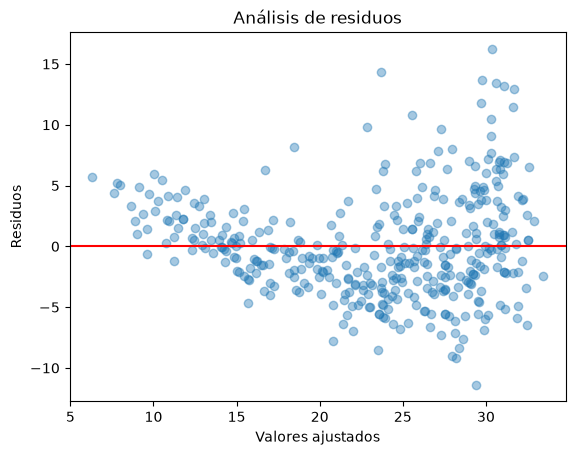

R² polinomial (horsepower): 0.688


In [12]:
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

autos = sns.load_dataset("mpg").dropna()
modelo = smf.ols("mpg ~ weight + horsepower + displacement + acceleration", data=autos).fit()
print(modelo.summary().tables[1])
print(f"R²: {modelo.rsquared:.3f} | R² ajustado: {modelo.rsquared_adj:.3f} | AIC: {modelo.aic:.1f} | p de F: {modelo.f_pvalue:.2e}")

# VIF de cada variable explicativa
Xv = autos[["weight", "horsepower", "displacement", "acceleration"]].assign(const=1)
print("VIF:", {c: round(variance_inflation_factor(Xv.values, i), 1) for i, c in enumerate(Xv.columns[:-1])})

# Residuos frente a valores ajustados
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.4); plt.axhline(0, color="red")
plt.xlabel("Valores ajustados"); plt.ylabel("Residuos"); plt.title("Análisis de residuos"); plt.show()

# Regresión polinomial de grado 2
poli = make_pipeline(PolynomialFeatures(2), LinearRegression()).fit(autos[["horsepower"]], autos["mpg"])
print("R² polinomial (horsepower):", round(poli.score(autos[["horsepower"]], autos["mpg"]), 3))

### Ideas para su ejemplo propio

- Partan con todas las variables de `TV_Sales.csv`, eliminen una a una las no significativas y muestren cómo cambian R² ajustado y AIC.
- Muestren el patrón curvo de los residuos en `mpg ~ horsepower` y cómo desaparece con un término cuadrático.
- Comparen Ridge y Lasso en `data_mtcars.csv`: qué variables descarta Lasso.

### Su explicación 

**La idea central: un chequeo médico del modelo.** Entrenar una regresión con `.fit()` es fácil; saber si quedó bien es lo difícil. Después de entrenar, le hacemos al modelo 7 "exámenes", y cada uno responde una pregunta distinta. Si algún examen sale mal, hay 4 "tratamientos": otras regresiones.

| # | Examen | Pregunta que responde | Regla rápida | Lámina |
|---|---|---|---|---|
| 1 | MSE, RMSE, MAE, MAPE | ¿Cuánto se equivoca? | Más bajo, mejor | 239 |
| 2 | R² y R² ajustado | ¿Cuánto explica? | Más alto, mejor (0 a 1) | 240, 243 |
| 3 | Prueba F y prueba t | ¿Sirve el modelo? ¿Y cada variable? | p < 0,05 = sí sirve | 241–242 |
| 4 | VIF | ¿Hay variables que se pisan? | VIF > 10 = grave | 244–245 |
| 5 | AIC y BIC | ¿Cuál modelo elijo? | Más bajo gana | 246–248 |
| 6 | Residuos | ¿Se cumplen los supuestos? | Nube sin patrón en torno a 0 | 249–250 |
| 7 | Leverage | ¿Hay puntos raros en X? | > 2p/n = revisar el punto | 251 |

**1 · Métricas de error.** Todas comparan el valor real $y$ con el predicho $\hat y$. Es como un GPS que predice tu hora de llegada: el **MAE** dice "en promedio fallo por 4 minutos"; el **MSE** eleva los errores al cuadrado, así que castiga mucho los errores grandes; el **RMSE** es la raíz del MSE y vuelve a las unidades de $y$; el **MAPE** da el error en porcentaje.

**2 · R² y R² ajustado.** $R^2 = 1 - \frac{SSE}{SST}$. Si la variación total de $y$ (SST) fuera una pizza, el R² es el pedazo que el modelo explica, y SSE es lo que sobra. Trampa: al agregar cualquier variable, aunque sea basura, el R² nunca baja. Por eso, para comparar modelos con distinto número de variables usamos el **R² ajustado**, que castiga cada variable extra. Con una sola X, $R^2 = Cor(X,Y)^2$.

**3 · Prueba F y prueba t.** Piénsenlo como fútbol. La **prueba F** pregunta si *el equipo completo* juega mejor que nada ($H_0$: todos los β = 0). La **prueba t** pregunta, *jugador por jugador*, si cada uno aporta ($H_0$: βᵢ = 0; $t = \hat\beta_i / \text{error estándar}$). Las dos entregan un **valor p**: qué tan probable sería ver estos datos si la variable no sirviera. Si p < 0,05, rechazamos $H_0$. Un p de 0,40 significa que no hay evidencia de que la variable aporte: es candidata a salir, y lo confirmamos viendo si mejoran el R² ajustado o el AIC.

**4 · Multicolinealidad y VIF.** Ocurre cuando dos variables explicativas cuentan la misma historia, como dos testigos que repiten lo mismo: el modelo no sabe a cuál darle el crédito y los coeficientes se vuelven inestables. Para cada $X_i$ hacemos una regresión contra las demás X y calculamos $VIF_i = \frac{1}{1-R_i^2}$. Un VIF > 10 se considera grave; un VIF de 15 significa que el 93% de esa variable ya lo explican las otras. La solución es simplificar el modelo o usar Ridge o Lasso.

**5 · AIC y BIC.** Suman dos partes: el **ajuste** (baja si el modelo se equivoca menos) y una **multa** por cada parámetro $p$ ($AIC = −2·logL + 2·p$; en el BIC es $BIC = −2·logL + p\ln(n)$, una multa más fuerte). Es como una pizzería que cobra por ingrediente: más ingredientes saben mejor, pero llega un punto en que no vale la pena. Por eso la curva tiene forma de U. **Gana el más bajo**: entre AIC 1416 y 1402, elegimos 1402. Solo se comparan modelos ajustados con los mismos datos y la misma $y$.

**6 · Análisis de residuos.** El residuo $y - \hat y$ es lo que el modelo no explicó. Si el modelo captó lo importante, lo que queda debe ser "ruido aburrido": centrado en 0, con distribución normal, varianza constante y **sin ningún patrón**. Un patrón curvo (forma de U) indica que falta curvatura; un embudo que se abre indica que la varianza no es constante. En ambos casos, el modelo lineal no es adecuado. Los residuos también sirven para detectar valores atípicos en $Y$.

**7 · Leverage (apalancamiento).** Mide qué tan lejos del centro de las X está una observación: $H_{ii}$, la diagonal de $H = X(X^tX)^{-1}X^t$. Funciona como un balancín: un punto lejos del centro tira la recta hacia él. Los $H_{ii}$ suman $p$, así que el promedio es $p/n$; un valor sobre $2p/n$ merece revisión. Resumen: residuo grande = raro en $Y$; leverage alto = raro en $X$.

**Otras regresiones (los tratamientos, láminas 253 a 258).** El error total es sesgo + varianza. Un modelo demasiado simple tiene sesgo alto (subajuste); uno demasiado complejo tiene varianza alta (sobreajuste).

- **Ridge (L2), "freno suave":** minimiza $|\varepsilon|^2 + \lambda\sum\beta_i^2$. Achica todos los coeficientes, pero ninguno llega a 0. Se usa contra el sobreajuste y la multicolinealidad.
- **Lasso (L1), "tijeras":** minimiza $|\varepsilon|^2 + \lambda\sum|\beta_i|$. Algunos coeficientes quedan exactamente en 0, así que también **elige variables**. Si λ es demasiado grande, el modelo queda sesgado. En sklearn, λ se llama `alpha`, y conviene estandarizar las X antes.
- **Polinomial, "curvas":** $Y = \beta_0 + \beta_1X + \beta_2X^2 + \dots$ Se usa cuando la relación es curva (subajuste). Si el grado es muy alto, aparece el sobreajuste. Sigue siendo lineal en los β.
- **Poisson, "conteos":** $\log(\lambda) = \beta_0 + \beta_1X_1 + \dots$ Se usa cuando $y$ es un conteo (0, 1, 2…), como llamadas por hora o goles por partido. El log asegura que la predicción nunca sea negativa; en esta distribución, la media y la varianza valen λ.

**Respuestas a las 4 preguntas:** (1) Con p = 0,40 no hay evidencia de que la variable aporte: la sacamos y comprobamos con el R² ajustado y el AIC. (2) Un VIF de 15 indica multicolinealidad grave. (3) Preferimos el AIC 1402, porque el más bajo equilibra mejor ajuste y simplicidad. (4) Cualquier patrón en los residuos (forma de U, embudo, residuos no centrados) indica que el modelo lineal no es adecuado.

### Ejemplo propio del subgrupo 2B

Cada paso reproduce un resultado de nuestra presentación. Usamos **dos datasets**: `TV_Sales.csv`, el mismo de las láminas, para leer el `summary()`, y `data_mtcars.csv`, con 32 autos y 10 características, para el caso principal. *Antes de partir, ejecuten la celda **Preparación del entorno** y el **Kit de inicio** del 2B.*

#### Paso 0 · Librerías y datos

In [13]:
# Ejemplo propio del subgrupo 2B
# Paso 0 · Librerías y datos
import numpy as np
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

# TV_Sales: ventas de televisores en 400 tiendas. Las categóricas pasan a dummies (lo vio el 2A).

tv = cargar_csv("TV_Sales.csv")
tv = pd.get_dummies(tv, columns=["shelve_loc", "city", "local"], drop_first=True, dtype=int)

# mtcars: rendimiento (mpg, millas por galón) de 32 autos según 10 características.
autos = cargar_csv("data_mtcars.csv")
print("TV_Sales:", tv.shape, "| mtcars:", autos.shape)
autos.head()

TV_Sales: (400, 8) | mtcars: (32, 12)


,model,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
0,Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
1,Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4
2,Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
3,Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1
4,Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2


#### Paso 1 · Exámenes 1, 2 y 3 en TV_Sales: errores, R² y prueba F *(láminas 239 a 242)*

Ajustamos `sales` con todas las variables. **Cómo leer la tabla:** `coef` es el efecto de la variable, `t` es el coef dividido por su error estándar, y `P>|t|` es el **valor p** de la prueba t. Debajo calculamos las métricas de error, el R² y el valor p de la prueba F.

**Ojo con el MAPE:** divide cada error por el valor real $y$. Una de las 400 tiendas vendió 0, y dividir por 0 hace que el porcentaje explote. Por eso calculamos el MAPE sin esa tienda.

In [14]:
# Paso 1 · Modelo con todas las variables de TV_Sales
f_todas = "sales ~ comp_price + income + price + shelve_loc_Good + shelve_loc_Medium + city_Yes + local_Yes"
m_tv1 = smf.ols(f_todas, data=tv).fit()
print(m_tv1.summary().tables[1])

pred = m_tv1.fittedvalues
con_ventas = tv.sales > 0   # una tienda vendió 0: el MAPE divide por y, así que la dejamos fuera
print(f"\nExamen 1 · RMSE: {mean_squared_error(tv.sales, pred) ** 0.5:.3f} | MAE: {mean_absolute_error(tv.sales, pred):.3f}"
      f" | MAPE: {100 * mean_absolute_percentage_error(tv.sales[con_ventas], pred[con_ventas]):.1f}% (sin la tienda con 0 ventas)")
print(f"Examen 2 · R²: {m_tv1.rsquared:.3f} | R² ajustado: {m_tv1.rsquared_adj:.3f}"
      f" | Cor(Y, Ŷ)² = {np.corrcoef(tv.sales, pred)[0, 1] ** 2:.3f} (es igual al R²)")
print(f"Examen 3 · p de la prueba F: {m_tv1.f_pvalue:.1e}  -> el modelo en conjunto sí sirve")

display(m_tv1)

                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             2.6934      0.637      4.225      0.000       1.440       3.947
comp_price            0.0066      0.000     16.270      0.000       0.006       0.007
income                0.0161      0.003      6.344      0.000       0.011       0.021
price                -0.0066      0.000    -24.974      0.000      -0.007      -0.006
shelve_loc_Good       4.8693      0.211     23.081      0.000       4.454       5.284
shelve_loc_Medium     1.9246      0.173     11.115      0.000       1.584       2.265
city_Yes              0.0860      0.155      0.553      0.580      -0.220       0.392
local_Yes             0.9713      0.149      6.540      0.000       0.679       1.263

Examen 1 · RMSE: 1.393 | MAE: 1.116 | MAPE: 21.6% (sin la tienda con 0 ventas)
Examen 2 · R²: 0.756 | R² ajustado: 0.752 | Cor(Y, Ŷ)² = 0.7

#### Paso 2 · Sacar la variable no significativa *(lámina 262, ex_0303)*

`city_Yes` tiene **p = 0,58**: estar en una ciudad no cambia las ventas de forma significativa. La sacamos y comparamos: el R² ajustado queda igual y el **AIC baja de 1416 a 1414**. Obtenemos un modelo más simple y con el mismo poder.

In [9]:
# Paso 2 · Mismo modelo, sin city_Yes
m_tv2 = smf.ols(f_todas.replace(" + city_Yes", ""), data=tv).fit()
pd.DataFrame({"R² ajustado": [m_tv1.rsquared_adj, m_tv2.rsquared_adj],
              "AIC": [m_tv1.aic, m_tv2.aic],
              "BIC": [m_tv1.bic, m_tv2.bic]},
             index=["con city_Yes", "sin city_Yes"]).round(3)

,R² ajustado,AIC,BIC
con city_Yes,0.752,1416.081,1448.013
sin city_Yes,0.752,1414.393,1442.333


### Ahora abordamos mtcars para justificar los ejemplos de la presentación *(caso principal)*
*Presentación https://docs.google.com/presentation/d/1DoYqy8Dc7V5eaZA7Bh99jJu_rgxbXtt5GxKpFgoqzlc/edit?usp=sharing*

#### Paso 3 · mtcars: el equipo gana, pero ningún jugador destaca

Ajustamos `mpg` con las 10 variables. La **prueba F** dice que el modelo sirve, pero **ninguna prueba t** sale significativa. ¿Cómo puede ser? Es la primera pista de multicolinealidad.

In [10]:
# Paso 3 · Modelo completo de mtcars (10 variables)
todas = " + ".join(autos.columns.drop(["model", "mpg"]))   # "cyl + disp + hp + ..."
completo = smf.ols("mpg ~ " + todas, data=autos).fit()
print(completo.summary().tables[1])
print(f"\np de la prueba F: {completo.f_pvalue:.1e}  -> el equipo sí sirve")
print("Variables con p < 0,05:", (completo.pvalues.drop("Intercept") < 0.05).sum(), "de 10  -> ningún jugador destaca")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     12.3034     18.718      0.657      0.518     -26.623      51.229
cyl           -0.1114      1.045     -0.107      0.916      -2.285       2.062
disp           0.0133      0.018      0.747      0.463      -0.024       0.050
hp            -0.0215      0.022     -0.987      0.335      -0.067       0.024
drat           0.7871      1.635      0.481      0.635      -2.614       4.188
wt            -3.7153      1.894     -1.961      0.063      -7.655       0.224
qsec           0.8210      0.731      1.123      0.274      -0.699       2.341
vs             0.3178      2.105      0.151      0.881      -4.059       4.694
am             2.5202      2.057      1.225      0.234      -1.757       6.797
gear           0.6554      1.493      0.439      0.665      -2.450       3.761
carb          -0.1994      0.829     -0.241      0.8

#### Paso 4 · Examen 4: VIF *(láminas 244 y 245)*

Para cada variable, `variance_inflation_factor` hace por dentro una regresión contra las demás y calcula $1/(1-R_i^2)$. En mtcars, **disp (21,6), cyl (15,4) y wt (15,2)** superan 10: la cilindrada, los cilindros y el peso cuentan la misma historia. En TV_Sales, en cambio, todos los VIF están cerca de 1.

disp    21.6
cyl     15.4
wt      15.2
hp       9.8
carb     7.9
qsec     7.5
gear     5.4
vs       5.0
am       4.6
drat     3.4
dtype: float64

VIF máximo en TV_Sales: 1.5


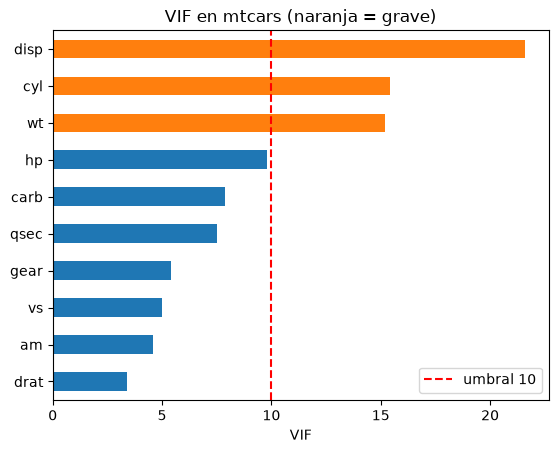

In [11]:
# Paso 4 · VIF de cada variable explicativa
def tabla_vif(df_x):
    X = df_x.assign(const=1)   # statsmodels necesita la constante para calcular bien el VIF
    return pd.Series({c: variance_inflation_factor(X.values, i) for i, c in enumerate(df_x.columns)}).round(1).sort_values(ascending=False)

vif_autos = tabla_vif(autos.drop(columns=["model", "mpg"]))
print(vif_autos)
print("\nVIF máximo en TV_Sales:", tabla_vif(tv.drop(columns="sales")).max())

colores = ["tab:orange" if v > 10 else "tab:blue" for v in vif_autos]
vif_autos.plot.barh(color=colores)
plt.axvline(10, color="red", ls="--", label="umbral 10")
plt.gca().invert_yaxis(); plt.xlabel("VIF"); plt.title("VIF en mtcars (naranja = grave)"); plt.legend(); plt.show()

#### Paso 5 · Examen 5: simplificar y comparar con AIC y BIC *(láminas 246 a 248)*

Nos quedamos con **peso (wt), aceleración (qsec) y transmisión manual (am)**. Con 3 variables en vez de 10, el **R² ajustado sube de 0,807 a 0,834** y el **AIC baja de 161,7 a 152,1**. Es un modelo mejor y más simple, y ahora sus tres variables tienen p < 0,05.

In [12]:
# Paso 5 · Modelo simple y comparación
simple = smf.ols("mpg ~ wt + qsec + am", data=autos).fit()
print("Valores p del modelo simple:\n", simple.pvalues.round(4), "\n")

pd.DataFrame({"variables": [10, 3],
              "R² ajustado": [completo.rsquared_adj, simple.rsquared_adj],
              "AIC": [completo.aic, simple.aic],
              "BIC": [completo.bic, simple.bic]},
             index=["completo", "simple"]).round(3)

Valores p del modelo simple:
 Intercept    0.1779
wt           0.0000
qsec         0.0002
am           0.0467
dtype: float64 



,variables,R² ajustado,AIC,BIC
completo,10,0.807,161.710,177.833
simple,3,0.834,152.119,157.982


#### Paso 6 · Examen 6: análisis de residuos *(láminas 249 y 250)*

Graficamos el residuo contra el valor ajustado. Con la recta `mpg ~ hp`, los residuos forman una **U**: al modelo le falta una curva. Al agregar $hp^2$, la U desaparece y queda una nube sin patrón. El histograma revisa que los residuos del modelo simple estén centrados en 0.

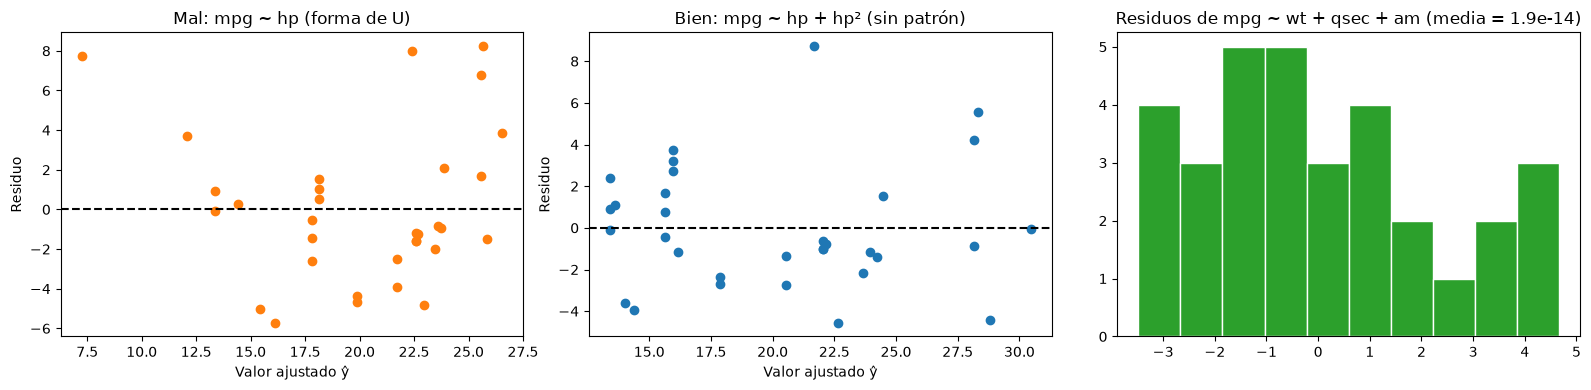

In [13]:
# Paso 6 · Residuos: recta vs curva, y el histograma del modelo simple
recta_hp = smf.ols("mpg ~ hp", data=autos).fit()
curva_hp = smf.ols("mpg ~ hp + I(hp**2)", data=autos).fit()

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for eje, m, titulo, color in [(ax[0], recta_hp, "Mal: mpg ~ hp (forma de U)", "tab:orange"),
                              (ax[1], curva_hp, "Bien: mpg ~ hp + hp² (sin patrón)", "tab:blue")]:
    eje.scatter(m.fittedvalues, m.resid, color=color)
    eje.axhline(0, color="black", ls="--")
    eje.set_xlabel("Valor ajustado ŷ"); eje.set_ylabel("Residuo"); eje.set_title(titulo)
ax[2].hist(simple.resid, bins=10, color="tab:green", edgecolor="white")
ax[2].set_title(f"Residuos de mpg ~ wt + qsec + am (media = {simple.resid.mean():.1e})")
plt.tight_layout(); plt.show()

#### Paso 7 · Examen 7: leverage *(lámina 251)*

`hat_matrix_diag` entrega el $H_{ii}$ de cada auto. Comprobamos la "regla de la suma" ($\sum H_{ii} = p$) y buscamos los autos que superan $2p/n$: **el Merc 230 y el Lincoln Continental** están lejos del centro de las X y vale la pena revisarlos. Esto no significa que sean errores.

In [14]:
# Paso 7 · Leverage del modelo simple
h = simple.get_influence().hat_matrix_diag
p, n = len(simple.params), len(autos)
print(f"Suma de leverage = {h.sum():.1f} (= p = {p}) | promedio p/n = {p / n:.3f} | umbral 2p/n = {2 * p / n:.3f}")

lev = pd.DataFrame({"auto": autos["model"], "leverage": h.round(3)}).sort_values("leverage", ascending=False)
lev[lev["leverage"] > 2 * p / n]

Suma de leverage = 4.0 (= p = 4) | promedio p/n = 0.125 | umbral 2p/n = 0.250


,auto,leverage
8,Merc 230,0.297
15,Lincoln Continental,0.264


#### Paso 8 · Ridge vs Lasso *(láminas 254 a 256, ex_0306)*

Estandarizamos las X con `StandardScaler` para que el castigo sea justo entre variables de distinta escala, y comparamos los coeficientes con `alpha = 1` (el λ de las láminas). Fíjense en `disp`: en OLS sale **positivo**, como si un motor más grande diera más rendimiento. Es la multicolinealidad confundiendo al modelo. **Ridge** lo achica, y **Lasso** lo deja en 0 junto con otras 6: solo sobreviven **cyl, hp y wt**.

In [15]:
# Paso 8 · Coeficientes de OLS, Ridge y Lasso con X estandarizadas
X = autos.drop(columns=["model", "mpg"])
y = autos["mpg"]

coefs = {}
for nombre, modelo in [("OLS", LinearRegression()), ("Ridge α=1", Ridge(alpha=1)), ("Lasso α=1", Lasso(alpha=1))]:
    pipe = make_pipeline(StandardScaler(), modelo).fit(X, y)
    coefs[nombre] = pipe[-1].coef_

tabla_coefs = pd.DataFrame(coefs, index=X.columns).round(2) + 0.0   # + 0.0 convierte -0.0 en 0.0
print("Lasso deja en 0:", list(tabla_coefs.index[tabla_coefs["Lasso α=1"] == 0]))
print("Lasso conserva:", list(tabla_coefs.index[tabla_coefs["Lasso α=1"] != 0]))
tabla_coefs

Lasso deja en 0: ['disp', 'drat', 'qsec', 'vs', 'am', 'gear', 'carb']
Lasso conserva: ['cyl', 'hp', 'wt']


,OLS,Ridge α=1,Lasso α=1
cyl,-0.20,-0.29,-1.53
disp,1.63,0.28,0.00
hp,-1.45,-1.01,-0.68
drat,0.41,0.49,0.00
wt,-3.58,-2.37,-2.50
qsec,1.44,0.87,0.00
vs,0.16,0.19,0.00
am,1.24,1.13,0.00
gear,0.48,0.50,0.00
carb,-0.32,-0.92,0.00


#### Paso 9 · Regresión polinomial *(lámina 257)*

Si los datos se curvan, curvamos la recta. Con $hp^2$, el **R² sube de 0,60 a 0,76** y el **AIC baja de 179 a 166**. Hacemos lo mismo en scikit-learn con `PolynomialFeatures(2)`, para mostrar que es equivalente.

Recta : R² = 0.602 | AIC = 179.2
Curva : R² = 0.756 | AIC = 165.6
R² con sklearn PolynomialFeatures(2): 0.756


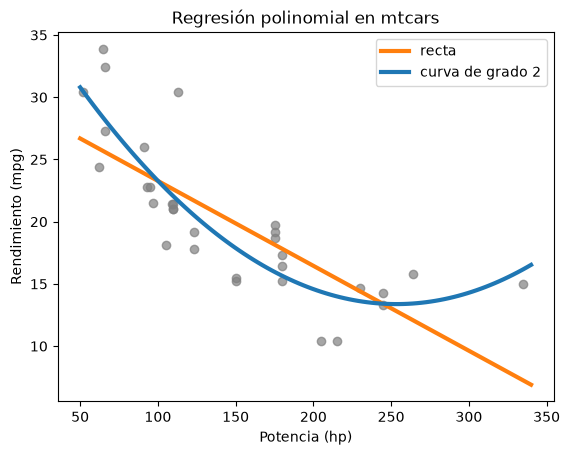

In [16]:
# Paso 9 · Recta vs curva de grado 2
print(f"Recta : R² = {recta_hp.rsquared:.3f} | AIC = {recta_hp.aic:.1f}")
print(f"Curva : R² = {curva_hp.rsquared:.3f} | AIC = {curva_hp.aic:.1f}")

poli = make_pipeline(PolynomialFeatures(2), LinearRegression()).fit(autos[["hp"]], y)
print("R² con sklearn PolynomialFeatures(2):", round(poli.score(autos[["hp"]], y), 3))

xs = pd.DataFrame({"hp": np.linspace(50, 340, 100)})
plt.scatter(autos["hp"], y, color="gray", alpha=0.7)
plt.plot(xs["hp"], recta_hp.predict(xs), color="tab:orange", lw=3, label="recta")
plt.plot(xs["hp"], curva_hp.predict(xs), color="tab:blue", lw=3, label="curva de grado 2")
plt.xlabel("Potencia (hp)"); plt.ylabel("Rendimiento (mpg)"); plt.title("Regresión polinomial en mtcars"); plt.legend(); plt.show()

#### Paso 10 · Regresión de Poisson *(lámina 258)*

`carb` (el número de carburadores) es un **conteo**. Modelamos $\log(\lambda)$ contra la potencia. Como hay un logaritmo, el coeficiente actúa multiplicando: **cada +50 hp multiplica los carburadores esperados por ≈ 1,32**. También comprobamos que la media y la varianza de `carb` son parecidas, como supone la distribución de Poisson.

In [17]:
# Paso 10 · Poisson: carb ~ hp
pois = smf.poisson("carb ~ hp", data=autos).fit(disp=0)
print(pois.params.round(4))
print(f"\nCada +50 hp multiplica los carburadores esperados por {np.exp(pois.params['hp'] * 50):.2f}")
print(f"Media de carb: {autos['carb'].mean():.2f} | varianza: {autos['carb'].var():.2f}")

Intercept    0.1490
hp           0.0055
dtype: float64

Cada +50 hp multiplica los carburadores esperados por 1.32
Media de carb: 2.81 | varianza: 2.61


### Ejemplo de la presentación: el caso mtcars en 12 líneas *(láminas 20 y 21)*

Esta celda tiene **el mismo código que mostramos en la lámina 21**, para correrlo en vivo. Cuenta la historia de la lámina 20 en cuatro pasos:

1. **Prueba F:** el modelo con las 10 variables sí sirve (p ≈ 0,0000004).
2. **Pruebas t:** pero ninguna variable tiene p < 0,05. ¿Contradicción?
3. **VIF:** `disp` (21,6), `cyl` (15,4) y `wt` (15,2) superan 10. Cuentan la misma historia, el modelo no sabe a quién darle el crédito, los errores estándar se inflan y los t se achican.
4. **Simplificar:** con `mpg ~ wt + qsec + am` (peso, aceleración y transmisión), el **R² ajustado sube de 0,807 a 0,834** y el **AIC baja de 161,7 a 152,1**. Con 3 variables en vez de 10, el modelo es mejor y más simple.

Al final, los residuos del modelo simple deberían verse como una nube sin patrón en torno a 0 (examen 6).

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     12.3034     18.718      0.657      0.518     -26.623      51.229
cyl           -0.1114      1.045     -0.107      0.916      -2.285       2.062
disp           0.0133      0.018      0.747      0.463      -0.024       0.050
hp            -0.0215      0.022     -0.987      0.335      -0.067       0.024
drat           0.7871      1.635      0.481      0.635      -2.614       4.188
wt            -3.7153      1.894     -1.961      0.063      -7.655       0.224
qsec           0.8210      0.731      1.123      0.274      -0.699       2.341
vs             0.3178      2.105      0.151      0.881      -4.059       4.694
am             2.5202      2.057      1.225      0.234      -1.757       6.797
gear           0.6554      1.493      0.439      0.665      -2.450       3.761
carb          -0.1994      0.829     -0.241      0.8

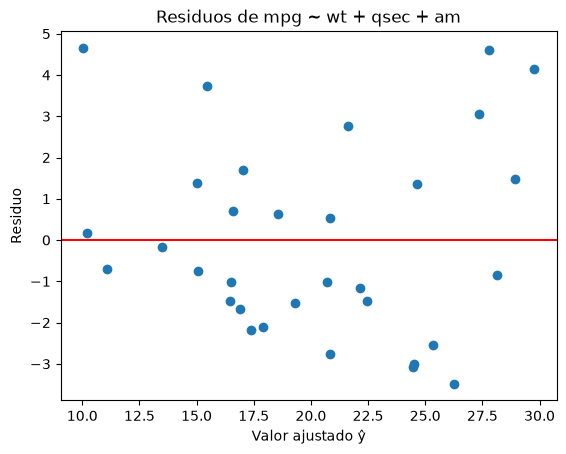

In [18]:
# Ejemplo de la presentación · el caso mtcars (láminas 20 y 21)
df = cargar_csv("data_mtcars.csv")
todas = " + ".join(df.columns.drop(["model", "mpg"]))
completo = smf.ols("mpg ~ " + todas, data=df).fit()
print(completo.summary().tables[1])                     # pruebas t: ningún p < 0,05
print("p de F:", completo.f_pvalue)                      # prueba F: el modelo sí sirve
X = df.drop(columns=["model", "mpg"]).assign(const=1)
print({c: round(variance_inflation_factor(X.values, i), 1)
       for i, c in enumerate(X.columns[:-1])})           # VIF: disp, cyl y wt sobre 10
simple = smf.ols("mpg ~ wt + qsec + am", data=df).fit()
for m in (completo, simple):
    print(round(m.rsquared_adj, 3), round(m.aic, 1))     # R² ajustado sube, AIC baja
plt.scatter(simple.fittedvalues, simple.resid); plt.axhline(0, color="red")
plt.xlabel("Valor ajustado ŷ"); plt.ylabel("Residuo"); plt.title("Residuos de mpg ~ wt + qsec + am"); plt.show()

### Ejercicio para la clase (2B)

**¿Recta o curva para el peso?** Con `data_mtcars.csv`, ajusten dos modelos:

- `mpg ~ wt` (la recta, ya está escrita)
- `mpg ~ wt + I(wt**2)` (la curva, les toca a ustedes)

Guarden en `respuesta_2b` el **AIC del mejor modelo, redondeado a entero**. *Pista: el AIC más bajo gana (atributo `.aic`).* Tienen 2 minutos.

In [ ]:
# Ejercicio 2B: sus compañeros escriben aquí su respuesta
df = cargar_csv("data_mtcars.csv")
recta = smf.ols("mpg ~ wt", data=df).fit()
curva = None  # TU CÓDIGO AQUÍ: el modelo mpg ~ wt + I(wt**2)
respuesta_2b = None  # TU CÓDIGO AQUÍ: el AIC más bajo de los dos, redondeado a entero

In [ ]:
# Verificación del ejercicio 2B (la escribe el subgrupo que presenta)
_df = cargar_csv("data_mtcars.csv")
_aic_recta = smf.ols("mpg ~ wt", data=_df).fit().aic
_aic_curva = smf.ols("mpg ~ wt + I(wt**2)", data=_df).fit().aic
revisar(lambda: respuesta_2b == round(min(_aic_recta, _aic_curva)),
        "Correcto. La curva gana: AIC 156 contra 164 de la recta.",
        "Todavía no. Ajusten la curva con I(wt**2) y comparen el .aic de los dos modelos.")

<details>
<summary><b>Solución del ejercicio 2B</b> (para revisar después; no la abran antes de intentarlo)</summary>

```python
curva = smf.ols("mpg ~ wt + I(wt**2)", data=df).fit()
respuesta_2b = round(min(recta.aic, curva.aic))   # 156
```

La recta tiene AIC 164,0 y la curva 156,0, así que gana la curva. Bonus: el R² ajustado también sube, de 0,745 a 0,807.
</details>

---
# Cierre: síntesis del capítulo

Completen esta tabla durante las presentaciones. Al final de la clase la revisamos entre todos.

| Algoritmo | ¿Clasificación, regresión o ambas? | Hiperparámetro principal | Necesita escalar | Una ventaja | Una desventaja |
|---|---|---|---|---|---|
| Regresión lineal | | | | | |
| Ridge / Lasso | Regresión | Es *alpha* en scikit (el λ) | Sí, la penalización λ depende de la escala de los coeficientes *beta* | Si existen demasiadas variables podemos reducir el peso de algunas (Ridge) que no impacten tanto o eliminarlas (Lasso) | Generamos sesgo, además de elegir un *alpha* |
| Regresión logística | | | | | |
| Árbol de decisión | | | | | |
| Naive Bayes | | | | | |
| KNN | | | | | |
| SVM | | | | | |
| Random forest | | | | | |
| Boosting | | | | | |

## Preguntas de repaso

1. ¿Por qué siempre evaluamos con datos que el modelo no vio durante el entrenamiento?
2. ¿Qué diferencia hay entre un parámetro y un hiperparámetro? Den un ejemplo de cada uno.
3. ¿Qué métrica usarían para un detector de fraude, donde los fraudes son el 1% de los casos?
4. ¿Qué algoritmos del capítulo necesitan escalar los datos y por qué?
5. Si tuvieran que elegir un solo algoritmo para empezar un proyecto nuevo de clasificación, ¿cuál elegirían y por qué?

**Recuerden** guardar el notebook en el repositorio, en la carpeta `ejercicios_estudiantes`.

Repositorio del curso: https://github.com/davidlealo/sic_ia_2026